In [1]:
import pandas as pd

In [2]:
import geopandas as gpd
import osmnx as ox
import networkx as nx
import folium
import matplotlib.pyplot as plt

In [3]:
ox.geocode_to_gdf("Yeongdeungpo-gu,Seoul,South Korea")

,geometry,bbox_west,bbox_south,bbox_east,bbox_north,place_id,osm_type,osm_id,lat,lon,class,type,place_rank,importance,addresstype,name,display_name
0,"POLYGON ((126.87802 37.55296, 126.87804 37.551...",126.878024,37.484973,126.94993,37.556252,223075808,relation,2414781,37.5262,126.8959,boundary,administrative,12,0.525144,borough,Yeongdeungpo-gu,"Yeongdeungpo-gu, Seoul, South Korea"


In [4]:
ox.graph_from_place("Yeongdeungpo-gu, Seoul, South Korea")

In [5]:
# 1) 영등포구 전체 도로(자전거 필터 없이) 받기
G = ox.graph_from_place("Yeongdeungpo-gu, Seoul, South Korea")

In [6]:
print(len(G.nodes), len(G.edges))

6432 18085


In [7]:
# 1-1) 영등포구 전체 도로(자전거가 다닐수있는 도로) 받기
G_bike = ox.graph_from_place(
    "Yeongdeungpo-gu, Seoul, South Korea",
    network_type="bike"
)


In [8]:
print(len(G_bike.nodes), len(G_bike.edges))

4202 11014


In [9]:
# 1-2) 영등포구 자전거 전용도로 받기
G_cycleway = ox.graph_from_place(
    "Yeongdeungpo-gu, Seoul, South Korea",
    custom_filter='["highway"="cycleway"]'
)


In [10]:
print(len(G_cycleway.nodes), len(G_cycleway.edges))

39 69


In [11]:
# 1-3) 영등포구 애매한 자전거도로(일반도로에 자전거차선) 포함
G_cycle_all = ox.graph_from_place(
    "Yeongdeungpo-gu, Seoul, South Korea",
    custom_filter='["cycleway"]'
)


In [12]:
print(len(G_cycle_all.nodes), len(G_cycle_all.edges))

13 24


In [13]:
G_cycleway = ox.graph_from_place(
    "Yeongdeungpo-gu, Seoul, South Korea",
    custom_filter='["highway"="cycleway"]'
)
print(len(G_cycleway.nodes), len(G_cycleway.edges))

39 69


In [14]:
G_lane = ox.graph_from_place(
    "Yeongdeungpo-gu, Seoul, South Korea",
    custom_filter='["cycleway"]'
)
print(len(G_lane.nodes), len(G_lane.edges))

13 24


In [15]:
import networkx as nx

G_bike_infra = nx.compose(G_cycleway, G_lane)

print(len(G_bike_infra.nodes), len(G_bike_infra.edges))

52 93


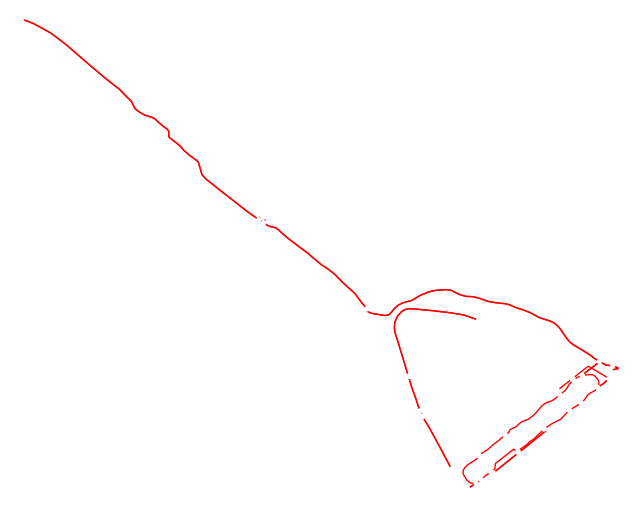

(<Figure size 800x800 with 1 Axes>, <Axes: >)

In [16]:
ox.plot_graph(G_bike_infra, node_size=15, edge_color="red", bgcolor="white")

In [17]:
import networkx as nx

G_undirected = G_bike_infra.to_undirected()
components = list(nx.connected_components(G_undirected))

print("덩어리 개수:", len(components))
for i, comp in enumerate(components):
    print(f"덩어리 {i+1}: 노드 {len(comp)}개")

덩어리 개수: 2
덩어리 1: 노드 39개
덩어리 2: 노드 13개


In [18]:
# 두 덩어리의 가장 가까운 지점 찾기
import itertools

# 두 덩어리를 따로 분리
comp_list = list(components)
comp1_nodes = comp_list[0]
comp2_nodes = comp_list[1]

# 각 덩어리의 노드 좌표 가져오기
def get_coords(nodes, G):
    return {n: (G.nodes[n]['y'], G.nodes[n]['x']) for n in nodes}

coords1 = get_coords(comp1_nodes, G_undirected)
coords2 = get_coords(comp2_nodes, G_undirected)

# 모든 쌍의 거리 계산해서 가장 가까운 쌍 찾기
from geopy.distance import distance

min_dist = float('inf')
closest_pair = None

for n1, c1 in coords1.items():
    for n2, c2 in coords2.items():
        d = distance(c1, c2).meters
        if d < min_dist:
            min_dist = d
            closest_pair = (n1, n2)

print("가장 가까운 노드 쌍:", closest_pair)
print("거리(미터):", round(min_dist, 1))

가장 가까운 노드 쌍: (5987527451, 13895055457)
거리(미터): 180.5


c:\Users\user\bike_network_analysis\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 50672 (\N{HANGUL SYLLABLE YEON}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\Users\user\bike_network_analysis\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 44208 (\N{HANGUL SYLLABLE GYEOL}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\Users\user\bike_network_analysis\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 54596 (\N{HANGUL SYLLABLE PIL}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\Users\user\bike_network_analysis\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 50836 (\N{HANGUL SYLLABLE YO}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\Users\user\bike_network_analysis\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 51648 (\N{H

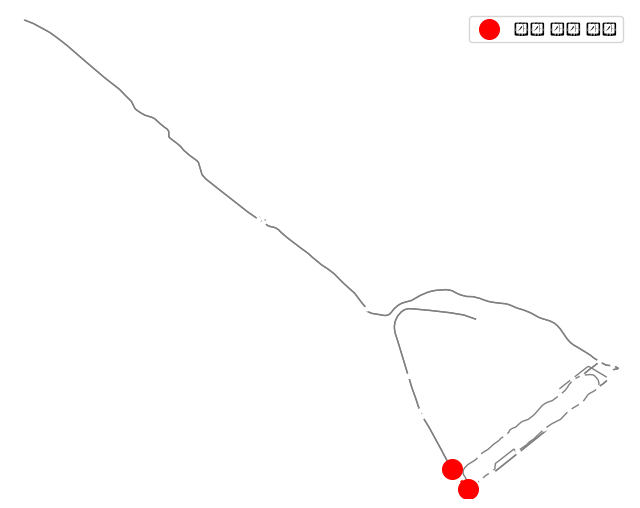

In [19]:
fig, ax = ox.plot_graph(
    G_bike_infra,
    node_size=15,
    edge_color="gray",
    bgcolor="white",
    show=False,
    close=False
)

n1, n2 = closest_pair
x1, y1 = G_undirected.nodes[n1]['x'], G_undirected.nodes[n1]['y']
x2, y2 = G_undirected.nodes[n2]['x'], G_undirected.nodes[n2]['y']

ax.scatter([x1, x2], [y1, y2], c="red", s=200, zorder=5, label="연결 필요 지점")
ax.plot([x1, x2], [y1, y2], c="red", linestyle="--", linewidth=2)
ax.legend()

import matplotlib.pyplot as plt
plt.show()

In [20]:
import matplotlib.pyplot as plt
plt.rcParams['font.family'] = 'Malgun Gothic'  # 윈도우 기본 한글 폰트
plt.rcParams['axes.unicode_minus'] = False

In [21]:
import pandas as pd

df_station = pd.read_csv("../data/station_master.csv", encoding="cp949")
df_station.head()

,대여소_ID,주소1,주소2,위도,경도
0,ST-999,서울특별시 양천구 목동서로 280,목동아파트 8단지 상가동,0.000000,0.000000
1,ST-998,서울특별시 양천구 목동서로 130,목동아파트 4단지 상가동,0.000000,0.000000
2,ST-997,서울특별시 양천구 목동중앙로 49,목동3단지 시내버스정류장,37.534390,126.869598
3,ST-996,서울특별시 양천구 남부순환로88길5-16,양강중학교앞 교차로,37.524334,126.850548
4,ST-995,서울특별시 양천구 중앙로 153 공중화장실,NaN,37.510597,126.857323


In [22]:
# 주소1에 '영등포구'가 들어간 행만 추출
df_ydp = df_station[df_station["주소1"].str.contains("영등포구", na=False)]

# 좌표가 0인 행(미입력) 제외
df_ydp = df_ydp[(df_ydp["위도"] != 0) & (df_ydp["경도"] != 0)]

print(df_ydp.shape)
df_ydp.head()

(207, 5)


,대여소_ID,주소1,주소2,위도,경도
297,ST-73,서울특별시 영등포구 여의동로 지하343,여의나루역 1번출구 앞,37.527157,126.931900
308,ST-72,서울특별시 영등포구 의사당대로 지하166,샛강역 1번출구 앞,37.517765,126.928413
319,ST-71,서울특별시 영등포구 의사당대로 166 샛강역,NaN,37.517586,126.929619
330,ST-70,서울특별시 영등포구 국제금융로 86,롯데캐슬 앞,37.520088,126.932365
342,ST-69,서울특별시 영등포구 국제금융로 106 행진빌딩,NaN,37.519131,126.933373


In [23]:
df_use = pd.read_csv("../data/20260909.csv", encoding="cp949", nrows=1000)
print(df_use.columns.tolist())
df_use.head()

['기준_날짜', '집계_기준', '기준_시간대', '시작_대여소_ID', '시작_대여소명', '종료_대여소_ID', '종료_대여소명', '전체_건수', '전체_이용_분', '전체_이용_거리']


,기준_날짜,집계_기준,기준_시간대,시작_대여소_ID,시작_대여소명,종료_대여소_ID,종료_대여소명,전체_건수,전체_이용_분,전체_이용_거리
0,20260909,출발시간,1005,ST-1660,자양3동_013_1,ST-1722,구의2동_049_1,1,13.0,2212.0
1,20260909,출발시간,1605,ST-1350,목5동_002_2,ST-1015,목5동_002_1,1,3.0,860.0
2,20260909,출발시간,735,ST-1015,목5동_002_1,ST-1350,목5동_002_2,1,3.0,778.0
3,20260909,출발시간,1610,ST-1344,한남동_030_1,ST-340,합정동_001_3,2,105.0,23869.0
4,20260909,출발시간,1800,ST-1179,대치1동_023_1,ST-1867,잠실3동_061_1,1,26.0,3869.0


In [24]:
# 영등포 구의 모든 대여소에서 몇 번 빌렸는지 정리

# 시작_대여소_ID별 하루 대여건수 합계
rent = df_use.groupby("시작_대여소_ID")["전체_건수"].sum().reset_index()
rent.columns = ["대여소_ID", "대여건수"]

# 영등포구 대여소(207개)와 합치기
df_ydp_use = df_ydp.merge(rent, on="대여소_ID", how="left")
print(df_ydp_use["대여건수"].isna().sum(), "개 대여소는 이용 기록 없음")
df_ydp_use.head()

136 개 대여소는 이용 기록 없음


,대여소_ID,주소1,주소2,위도,경도,대여건수
0,ST-73,서울특별시 영등포구 여의동로 지하343,여의나루역 1번출구 앞,37.527157,126.931900,NaN
1,ST-72,서울특별시 영등포구 의사당대로 지하166,샛강역 1번출구 앞,37.517765,126.928413,2.0
2,ST-71,서울특별시 영등포구 의사당대로 166 샛강역,NaN,37.517586,126.929619,1.0
3,ST-70,서울특별시 영등포구 국제금융로 86,롯데캐슬 앞,37.520088,126.932365,NaN
4,ST-69,서울특별시 영등포구 국제금융로 106 행진빌딩,NaN,37.519131,126.933373,NaN


In [25]:
# 136개 대여소는 이용 기록 없음 -> 207개 중 71개만 0909 대여 기록이 있음

In [26]:
import glob

# 202609로 시작하는 파일 병합
files = sorted(glob.glob("../data/202609*.csv"))
print(len(files), "개 파일")

df_all = pd.concat(
    [pd.read_csv(f, encoding="cp949") for f in files],
    ignore_index=True
)

# 날짜별 총 대여건수 (이상한 날 확인용)
print(df_all.groupby("기준_날짜")["전체_건수"].sum())

14 개 파일


기준_날짜
20260901     72858
20260902    280146
20260903    298956
20260904    318632
20260905    290238
20260906    266618
20260907    310376
20260908    318406
20260909    323722
20260910    321690
20260911    336028
20260912    291168
20260913    252336
20260914    322710
Name: 전체_건수, dtype: int64


In [27]:
# 영등포구 대여소만 남기기 + 대여소별 하루 평균 대여건수 (14일 전체)
ydp_ids = df_ydp["대여소_ID"]
df_ydp_use = df_all[df_all["시작_대여소_ID"].isin(ydp_ids)]

daily = df_ydp_use.groupby(["시작_대여소_ID", "기준_날짜"])["전체_건수"].sum().reset_index()
avg = daily.groupby("시작_대여소_ID")["전체_건수"].mean().reset_index()
avg.columns = ["대여소_ID", "일평균_대여건수"]

df_demand = df_ydp.merge(avg, on="대여소_ID", how="left")
print(df_demand["일평균_대여건수"].describe())
print("기록 없는 대여소:", df_demand["일평균_대여건수"].isna().sum())

count    174.000000
mean     155.660593
std      110.132863
min       11.692308
25%       74.285714
50%      132.071429
75%      212.678571
max      633.692308
Name: 일평균_대여건수, dtype: float64
기록 없는 대여소: 33


In [28]:
# 대여소 일평균이 부풀려졌는지 점검 (0-7일이 있는지)

days = daily.groupby("시작_대여소_ID")["기준_날짜"].nunique()
print(days.describe())
print("7일 미만 대여소:", (days < 7).sum())

count    174.000000
mean      13.879310
std        0.495445
min        9.000000
25%       14.000000
50%       14.000000
75%       14.000000
max       14.000000
Name: 기준_날짜, dtype: float64
7일 미만 대여소: 0


In [29]:
df_age = pd.read_csv("../data/ydp_age_pop_2026-09.csv", encoding="cp949")

print(df_age.columns.tolist())
print(df_age.head(25))

['행정구역(동읍면)별', '항목', '2026.09', '2026.09.1', '2026.09.2', '2026.09.3', '2026.09.4']
    행정구역(동읍면)별        항목  2026.09 2026.09.1 2026.09.2 2026.09.3 2026.09.4
0   행정구역(동읍면)별        항목        계    0 - 4세    5 - 9세  10 - 14세  15 - 19세
1        서울특별시  총인구수 (명)  9279861    207736    242443    340984    372123
2        영등포본동  총인구수 (명)    20185       542       427       502       523
3         영등포동  총인구수 (명)    31195       576       389       405       443
4          여의동  총인구수 (명)    33775      1067      1144      1475      1393
5        당산제1동  총인구수 (명)    21001       533       370       399       480
6        당산제2동  총인구수 (명)    36071      1060      1076      1159      1103
7          도림동  총인구수 (명)    17545       387       271       381       401
8          문래동  총인구수 (명)    31095      1179      1264      1536      1371
9        양평제1동  총인구수 (명)    19685       700       514       559       566
10       양평제2동  총인구수 (명)    22348       789       581       594       700
11       신길제1동  총인구수 (명)    

In [30]:
# 동별 어린이·청소년(0~19세) 비율 계산
df_age = pd.read_csv("../data/ydp_age_pop_2026-09.csv", encoding="cp949")

# 헤더가 두 줄이라 컬럼명 직접 지정, 첫 행(진짜 헤더)과 서울특별시 행 제거
df_age.columns = ["행정동", "항목", "계", "0_4세", "5_9세", "10_14세", "15_19세"]
df_age = df_age.iloc[1:]
df_age = df_age[df_age["행정동"] != "서울특별시"].reset_index(drop=True)

# 앞뒤 공백 제거 + 숫자로 변환
df_age["행정동"] = df_age["행정동"].str.strip()
num_cols = ["계", "0_4세", "5_9세", "10_14세", "15_19세"]
df_age[num_cols] = df_age[num_cols].apply(pd.to_numeric)

df_age["청소년인구"] = df_age[["0_4세", "5_9세", "10_14세", "15_19세"]].sum(axis=1)
df_age["청소년비율"] = df_age["청소년인구"] / df_age["계"]

print(df_age[["행정동", "계", "청소년인구", "청소년비율"]].sort_values("청소년비율", ascending=False))

      행정동      계  청소년인구     청소년비율
14  신길제7동  19277   3568  0.185091
6     문래동  31095   5350  0.172053
2     여의동  33775   5079  0.150377
12  신길제5동   9481   1257  0.132581
4   당산제2동  36071   4398  0.121926
8   양평제2동  22348   2664  0.119205
7   양평제1동  19685   2339  0.118821
10  신길제3동  16030   1881  0.117342
11  신길제4동  11753   1371  0.116651
0   영등포본동  20185   1994  0.098786
13  신길제6동  17713   1737  0.098064
15  대림제1동  13178   1191  0.090378
17  대림제3동  20569   1778  0.086441
3   당산제1동  21001   1782  0.084853
5     도림동  17545   1440  0.082075
9   신길제1동  18852   1368  0.072565
16  대림제2동  11403    670  0.058756
1    영등포동  31195   1813  0.058118


In [31]:
# 영등포구 행정동 경계 읽기 (통계청 SGIS 2025.06 기준)
gdf_dong = gpd.read_file("../data/bnd_dong_11190_2025_2Q.shp")
print(gdf_dong.shape)
print(gdf_dong.crs)
print(gdf_dong.drop(columns="geometry").head(20))

(18, 4)
EPSG:5179
   BASE_DATE    ADM_CD ADM_NM
0   20250630  11190540    여의동
1   20250630  11190550   당산1동
2   20250630  11190560   당산2동
3   20250630  11190610   양평1동
4   20250630  11190620   양평2동
5   20250630  11190630   신길1동
6   20250630  11190650   신길3동
7   20250630  11190660   신길4동
8   20250630  11190670   신길5동
9   20250630  11190680   신길6동
10  20250630  11190690   신길7동
11  20250630  11190700   대림1동
12  20250630  11190710   대림2동
13  20250630  11190720   대림3동
14  20250630  11190730  영등포본동
15  20250630  11190740   영등포동
16  20250630  11190750    도림동
17  20250630  11190760    문래동


In [32]:
# 컬럼 이름 확인
print(gdf_dong.drop(columns="geometry").head(20))
print(gdf_dong.crs)

   BASE_DATE    ADM_CD ADM_NM
0   20250630  11190540    여의동
1   20250630  11190550   당산1동
2   20250630  11190560   당산2동
3   20250630  11190610   양평1동
4   20250630  11190620   양평2동
5   20250630  11190630   신길1동
6   20250630  11190650   신길3동
7   20250630  11190660   신길4동
8   20250630  11190670   신길5동
9   20250630  11190680   신길6동
10  20250630  11190690   신길7동
11  20250630  11190700   대림1동
12  20250630  11190710   대림2동
13  20250630  11190720   대림3동
14  20250630  11190730  영등포본동
15  20250630  11190740   영등포동
16  20250630  11190750    도림동
17  20250630  11190760    문래동
EPSG:5179


In [33]:
# 인구 표의 '제' 제거해서 경계 파일 이름과 맞추기
df_age["ADM_NM"] = df_age["행정동"].str.replace("제", "", regex=False)
print("이름 불일치:", set(gdf_dong["ADM_NM"]) ^ set(df_age["ADM_NM"]))  # set()이면 일치

# 경계에 청소년 비율 붙이기
gdf_dong2 = gdf_dong.merge(df_age[["ADM_NM", "계", "청소년인구", "청소년비율"]], on="ADM_NM")

# 대여소 좌표(위도·경도) -> 경계와 같은 좌표계(5179)로 변환 후 어느 동 안인지 계산
gdf_st = gpd.GeoDataFrame(
    df_demand,
    geometry=gpd.points_from_xy(df_demand["경도"], df_demand["위도"]),
    crs="EPSG:4326",
).to_crs(gdf_dong2.crs)
gdf_st = gpd.sjoin(gdf_st, gdf_dong2[["ADM_NM", "청소년비율", "geometry"]], how="left", predicate="within")

print("동 안에 못 들어간 대여소:", gdf_st["ADM_NM"].isna().sum(), "/", len(gdf_st))
print(gdf_st.groupby("ADM_NM")["일평균_대여건수"].agg(["count", "mean"]).round(1))

이름 불일치: set()
동 안에 못 들어간 대여소: 1 / 207
        count   mean
ADM_NM              
당산1동       10  196.5
당산2동       14  261.0
대림1동        2   77.2
대림2동        2   70.0
대림3동        6   90.8
도림동         5  123.5
문래동        15  186.5
신길1동        4   95.0
신길3동        7   80.1
신길4동        2   83.8
신길5동        0    NaN
신길6동        3  160.1
신길7동        7   89.3
양평1동       11  178.9
양평2동        8  204.3
여의동        52  125.5
영등포동       15  218.4
영등포본동      10  151.2


In [34]:
# 신길 5동의 값이 NAN인 이유
# 신길5동 대여소가 몇 개이고, 이용 기록이 있는지 확인
print(gdf_st[gdf_st["ADM_NM"] == "신길5동"][["대여소_ID", "일평균_대여건수"]])
print("전체 대여소 수:", len(gdf_st))
print("이용 기록 없는 대여소 수:", gdf_st["일평균_대여건수"].isna().sum())

# 다음행 확인결과 신길 5동내의 대여소 2개 모두 14일간 이용기록이없음

      대여소_ID  일평균_대여건수
119   ST-283       NaN
169  ST-1981       NaN
전체 대여소 수: 207
이용 기록 없는 대여소 수: 33


In [35]:
# 동 안에 못 들어간 대여소 확인
print(gdf_st[gdf_st["ADM_NM"].isna()][["대여소_ID", "주소1", "주소2", "위도", "경도", "일평균_대여건수"]])


      대여소_ID                  주소1       주소2         위도          경도   일평균_대여건수
198  ST-1540  서울특별시 영등포구 가마산로 315  신동아아파트 앞  37.498241  126.893982  83.571429


In [36]:
# 동을 못 찾은 대여소를 가장 가까운 동에 붙이기
miss = gdf_st["ADM_NM"].isna()
near = gpd.sjoin_nearest(
    gdf_st.loc[miss, ["대여소_ID", "geometry"]],
    gdf_dong2[["ADM_NM", "청소년비율", "geometry"]],
    distance_col="거리m",
)
near = near[~near.index.duplicated()]
print(near[["대여소_ID", "ADM_NM", "거리m"]])

gdf_st.loc[near.index, ["ADM_NM", "청소년비율"]] = near[["ADM_NM", "청소년비율"]]

# 이용 기록 있는 대여소만 남기기 (모델 학습용)
gdf_model = gdf_st.dropna(subset=["일평균_대여건수"]).reset_index(drop=True)
print(gdf_model.shape, gdf_model["ADM_NM"].isna().sum())

      대여소_ID ADM_NM       거리m
198  ST-1540   대림3동  2.943248
(174, 10) 0


In [37]:
# 수요 모델 변수 넣기
# 어떤 곳이 얼마나 탈지"를 변수들로 맞히는 계산식

In [38]:
# 동별 인구밀도 계산 (경계 면적 이용, 5179 좌표계는 단위가 m)
gdf_dong2["면적km2"] = gdf_dong2.geometry.area / 1_000_000
gdf_dong2["인구밀도"] = gdf_dong2["계"] / gdf_dong2["면적km2"]

gdf_model = gdf_model.merge(gdf_dong2[["ADM_NM", "인구밀도"]], on="ADM_NM", how="left")
print(gdf_model[["ADM_NM", "청소년비율", "인구밀도"]].drop_duplicates("ADM_NM").round(2))

    ADM_NM  청소년비율      인구밀도
0      여의동   0.15   4005.90
21    당산2동   0.12  22831.76
25    양평2동   0.12   7779.99
26    영등포동   0.06  22747.22
27    당산1동   0.08  28198.38
29     문래동   0.17  17416.24
32    신길3동   0.12  30844.61
33    양평1동   0.12  20206.31
46    신길6동   0.10  28666.50
65   영등포본동   0.10  23866.42
66    신길1동   0.07  26096.62
71    신길7동   0.19  29808.57
74    대림3동   0.09  22332.81
76     도림동   0.08  29968.13
86    대림1동   0.09  26429.38
95    신길4동   0.12  36458.73
163   대림2동   0.06  19930.84


In [39]:
# 서울시 지하철역 정보(위도, 경도) => 수요모델의 넣을 '지하철역 까지의 거리'변수 

# osm에서 영등포구 + 2km 여유 범위의 지하철역 가져오기 (경계 근처 대여소의 최근접 역 확보용)
area = gdf_dong2.union_all().buffer(2000)  # 좌표계 단위 (m)
area_wgs = gpd.GeoSeries([area], crs=gdf_dong2.crs).to_crs(4326).iloc[0]

gdf_subway = ox.features_from_polygon(area_wgs, tags={"station": "subway"})
print(len(gdf_subway))
print(gdf_subway[["name", "geometry"]].head(20))

56
                       name                    geometry
element id                                             
node    1849176201    국회의사당  POINT (126.91796 37.52802)
        1994702339       노들  POINT (126.95355 37.51297)
        3834732263       흑석  POINT (126.96395 37.50838)
        5774282517       구로  POINT (126.88251 37.50345)
        5840686670      노량진  POINT (126.94204 37.51424)
        5900362272       대방  POINT (126.92648 37.51336)
        5916874391       합정  POINT (126.91366 37.54936)
        5919544685     홍대입구  POINT (126.92691 37.55735)
        5937884691       신촌  POINT (126.93691 37.55515)
        6033312683       당산   POINT (126.90248 37.5346)
        6033314412       문래  POINT (126.89487 37.51838)
        6033314425      신도림  POINT (126.89123 37.50894)
        6033314429  구로디지털단지  POINT (126.90159 37.48528)
        6033314471      신대방  POINT (126.91339 37.48759)
        6033314481       신림  POINT (126.92968 37.48423)
        6033364440     양천구청   POINT (126.8659

In [40]:
# 대여소별 가장 가까운 지하철역까지 거리(m)
subway = gdf_subway.reset_index()[["name", "geometry"]].to_crs(gdf_model.crs)
subway["geometry"] = subway.geometry.centroid
subway = subway.rename(columns={"name": "가까운역"})

gdf_model = gdf_model.drop(columns=["index_right"], errors="ignore")
gdf_model = gdf_model.sjoin_nearest(subway, distance_col="역거리m")
gdf_model = gdf_model[~gdf_model.index.duplicated()]
print(gdf_model["역거리m"].describe().round(0))

count     174.0
mean      438.0
std       218.0
min        15.0
25%       312.0
50%       451.0
75%       570.0
max      1102.0
Name: 역거리m, dtype: float64


In [41]:
# 평균 438m, 대여소가 역에서 5분 근처에 존재함
# 최장 1102m

# 가설: 역이 가까울 수록 따릉이 탑승자 수가 증가하는가

In [42]:
# 수요 모델: 역거리·인구밀도·청소년비율로 대여소 일평균 대여건수 예측
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.metrics import r2_score, mean_absolute_error

features = ["역거리m", "인구밀도", "청소년비율"]
X = gdf_model[features]
y = gdf_model["일평균_대여건수"]

# 같은 동 대여소는 인구밀도·청소년비율이 같아서, 동 단위로 나눠서 검증해야 점수가 부풀지 않아요
rf = RandomForestRegressor(n_estimators=300, random_state=42)
pred = cross_val_predict(rf, X, y, cv=GroupKFold(n_splits=5), groups=gdf_model["ADM_NM"])
print("R2:", round(r2_score(y, pred), 2), "/ 평균오차:", round(mean_absolute_error(y, pred), 1), "건")

# 어떤 변수가 중요한지
rf.fit(X, y)
print(dict(zip(features, rf.feature_importances_.round(2))))

R2: -0.29 / 평균오차: 97.1 건
{'역거리m': np.float64(0.7), '인구밀도': np.float64(0.16), '청소년비율': np.float64(0.14)}


In [43]:
gdf_model.drop(columns="geometry")

,대여소_ID,주소1,주소2,위도,경도,일평균_대여건수,ADM_NM,청소년비율,인구밀도,index_right,가까운역,역거리m
0,ST-73,서울특별시 영등포구 여의동로 지하343,여의나루역 1번출구 앞,37.527157,126.931900,211.714286,여의동,0.150377,4005.899084,20,여의나루,65.020185
1,ST-72,서울특별시 영등포구 의사당대로 지하166,샛강역 1번출구 앞,37.517765,126.928413,185.714286,여의동,0.150377,4005.899084,42,샛강,46.185848
2,ST-71,서울특별시 영등포구 의사당대로 166 샛강역,NaN,37.517586,126.929619,151.142857,여의동,0.150377,4005.899084,42,샛강,120.739045
3,ST-70,서울특별시 영등포구 국제금융로 86,롯데캐슬 앞,37.520088,126.932365,162.428571,여의동,0.150377,4005.899084,42,샛강,470.807250
4,ST-69,서울특별시 영등포구 국제금융로 106 행진빌딩,NaN,37.519131,126.933373,76.000000,여의동,0.150377,4005.899084,42,샛강,490.844377
...,...,...,...,...,...,...,...,...,...,...,...,...
169,ST-1539,서울특별시 영등포구 선유로 213,선유중학교 정문,37.532101,126.894440,246.142857,양평2동,0.119205,7779.994042,46,선유도,640.145911
170,ST-1353,서울특별시 영등포구 도신로29길 28,영등포 푸르지오 아파트,37.513229,126.904465,188.571429,영등포본동,0.098786,23866.420964,10,문래,1022.608088
171,ST-1323,서울특별시 영등포구 도영로 18,쌍용플레티넘오피스텔,37.507931,126.895233,232.857143,도림동,0.082075,29968.126967,52,신도림,342.402066
172,ST-1321,서울특별시 영등포구 경인로112길 1,SK영등포주유소,37.518284,126.912636,94.428571,영등포동,0.058118,22747.220992,44,신길,339.453896


In [ ]:
# 끊긴 두 덩어리를 잇는 후보 지점과 그 주변 수요·형평성 계산
from shapely.geometry import Point, LineString

# 두 덩어리 노드 좌표 (경도 x, 위도 y)를 5179로 변환
comps = [list(c) for c in nx.connected_components(G_bike_infra.to_undirected())]
nodes = pd.DataFrame(
    [(n, d["x"], d["y"], i) for i, c in enumerate(comps) for n in c for d in [G_bike_infra.nodes[n]]],
    columns=["node", "x", "y", "덩어리"],
)
gn = gpd.GeoDataFrame(nodes, geometry=gpd.points_from_xy(nodes.x, nodes.y), crs="EPSG:4326").to_crs(5179)

# 두 덩어리 사이 거리가 가장 짧은 노드 쌍 5개 = 연결 후보
a, b = gn[gn["덩어리"] == 0], gn[gn["덩어리"] == 1]
pairs = [(p.node, q.node, p.geometry.distance(q.geometry), LineString([p.geometry, q.geometry]))
         for p in a.itertuples() for q in b.itertuples()]
cand = gpd.GeoDataFrame(sorted(pairs, key=lambda t: t[2])[:5],
                        columns=["노드A", "노드B", "거리m", "geometry"], crs=5179)

# 후보 연결선 중심에서 500m 안 대여소의 수요 합계 + 소속 동 청소년비율
rows = []
for r in cand.itertuples():
    mid = r.geometry.centroid
    near = gdf_model[gdf_model.geometry.distance(mid) <= 500]
    dong = gdf_dong2[gdf_dong2.contains(mid)]["ADM_NM"]
    rows.append({"노드A": r.노드A, "노드B": r.노드B, "연결거리m": round(r.거리m),
                 "500m내 대여소": len(near), "잠재수요(일평균 합)": round(near["일평균_대여건수"].sum()),
                 "소속동": dong.iloc[0] if len(dong) else None,
                 "청소년비율": round(near["청소년비율"].mean(), 3) if len(near) else None})
df_cand = pd.DataFrame(rows)
print(df_cand)

# 이으면 늘어날 량이 아니고 "연결 지점 인근의 현재 이용 수요"

          노드A          노드B  연결거리m  500m내 대여소  잠재수요(일평균 합)  소속동  청소년비율
0  5987527451  13895055457    180          5         1135  여의동  0.132
1  2604499995  13895055457    203          5          988  여의동  0.150
2  2604500762  13895055457    219          8         1335  여의동  0.150
3  2604500761  13895055457    220          8         1335  여의동  0.150
4  2604499998  13895055457    224          6         1121  여의동  0.150


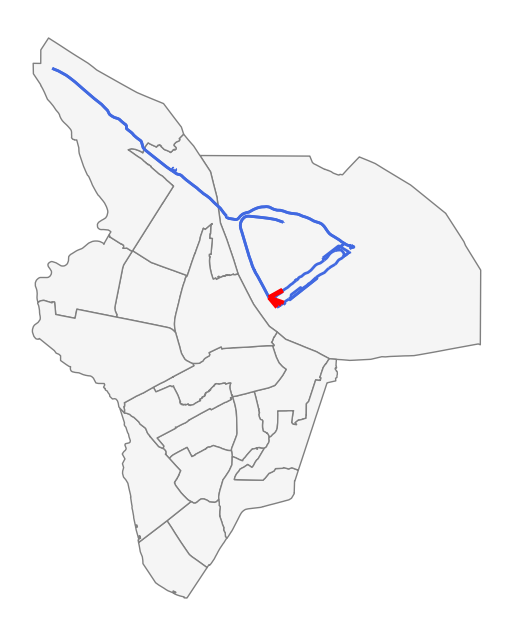

In [ ]:
# 1) 자전거도로 연결 후보
import matplotlib.pyplot as plt
plt.rcParams["font.family"] = "Malgun Gothic"

# 2) 자전거도로 선을 5179로 변환
edges = ox.graph_to_gdfs(G_bike_infra, nodes=False).to_crs(5179)

fig, ax = plt.subplots(figsize=(8, 8))
gdf_dong2.plot(ax=ax, color="whitesmoke", edgecolor="gray")
edges.plot(ax=ax, color="royalblue", linewidth=2)
cand.plot(ax=ax, color="red", linewidth=3)
ax.set_axis_off()
plt.show()

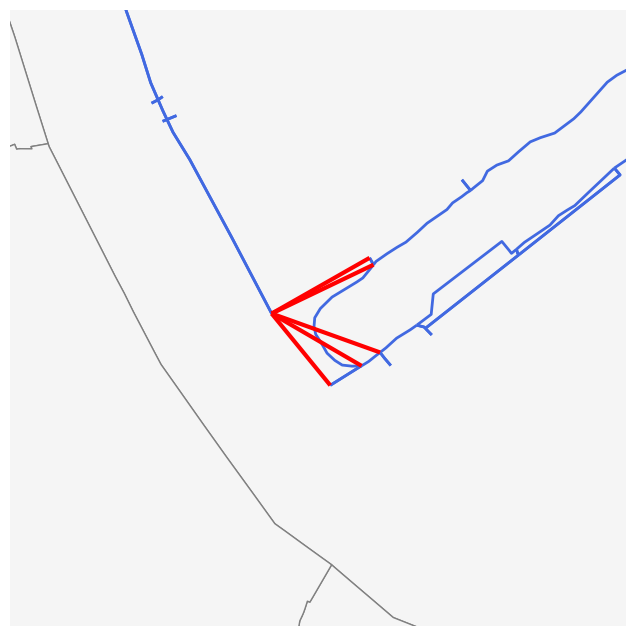

In [ ]:
# 지도 중심점 구하기(알맞는곳 보여주기)
c = cand.union_all().centroid

fig, ax = plt.subplots(figsize=(8, 8))
gdf_dong2.plot(ax=ax, color="whitesmoke", edgecolor="gray")
edges.plot(ax=ax, color="royalblue", linewidth=2)
cand.plot(ax=ax, color="red", linewidth=3)
ax.set_xlim(c.x - 600, c.x + 600)
ax.set_ylim(c.y - 600, c.y + 600)
ax.set_axis_off()
plt.show()

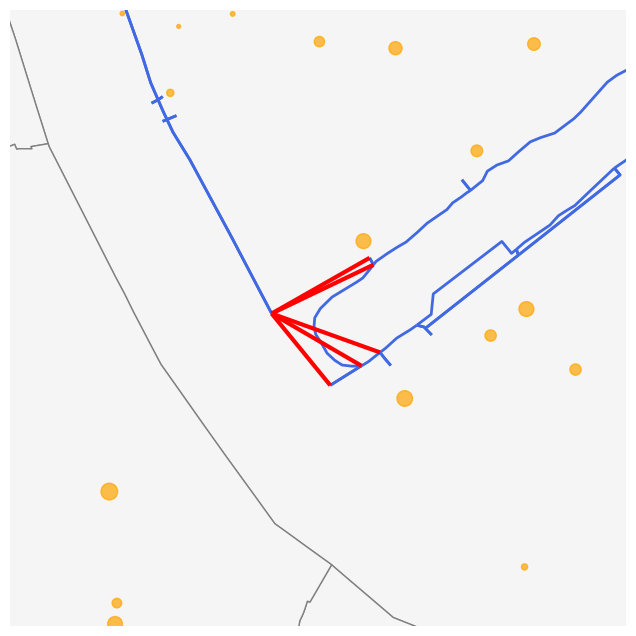

In [48]:
#대여소 표시
c = cand.union_all().centroid

fig, ax = plt.subplots(figsize=(8, 8))
gdf_dong2.plot(ax=ax, color="whitesmoke", edgecolor="gray")
edges.plot(ax=ax, color="royalblue", linewidth=2)
cand.plot(ax=ax, color="red", linewidth=3)
gdf_model.plot(ax=ax, color="orange", alpha=0.7, markersize=gdf_model["일평균_대여건수"] / 2)
ax.set_xlim(c.x - 600, c.x + 600)
ax.set_ylim(c.y - 600, c.y + 600)
ax.set_axis_off()
plt.show()

In [49]:
# 대여소 표시 (원 크기 = 일평균 대여건수)
# 결과: 연결 후보 주변 500m 안에 대여소 5~8개, 큰 편차 없음

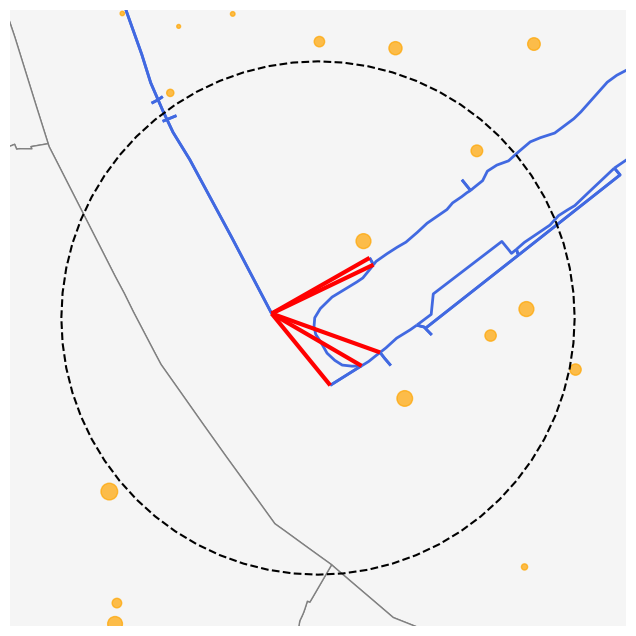

In [50]:
# 연결 후보 중심에 반경 500m 원 추가
c = cand.union_all().centroid

fig, ax = plt.subplots(figsize=(8, 8))
gdf_dong2.plot(ax=ax, color="whitesmoke", edgecolor="gray")
edges.plot(ax=ax, color="royalblue", linewidth=2)
cand.plot(ax=ax, color="red", linewidth=3)
gdf_model.plot(ax=ax, color="orange", alpha=0.7, markersize=gdf_model["일평균_대여건수"] / 2)
gpd.GeoSeries([c.buffer(500)], crs=5179).boundary.plot(ax=ax, color="black", linestyle="--")
ax.set_xlim(c.x - 600, c.x + 600)
ax.set_ylim(c.y - 600, c.y + 600)
ax.set_axis_off()
plt.show()

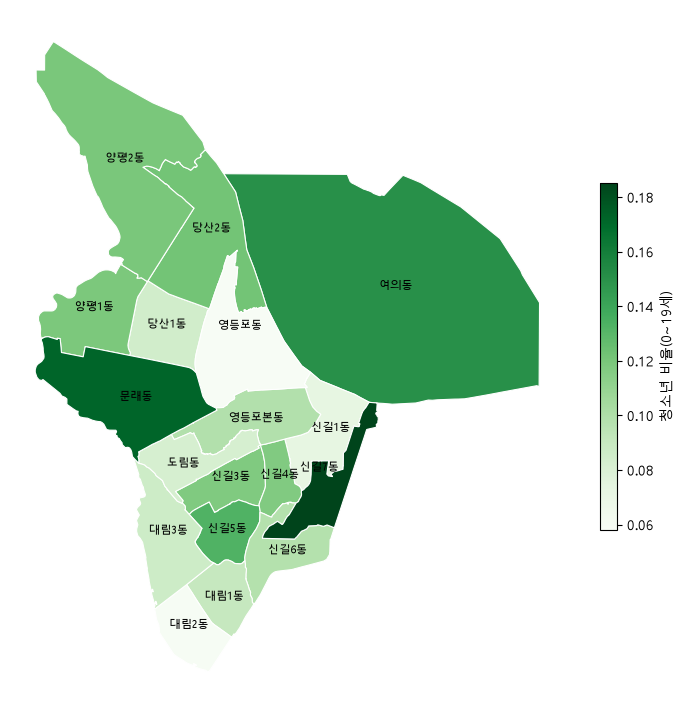

In [52]:
# 동별 청소년비율 지도
fig, ax = plt.subplots(figsize=(9, 9))
gdf_dong2.plot(ax=ax, column="청소년비율", cmap="Greens", edgecolor="white", linewidth=0.8,
               legend=True, legend_kwds={"label": "청소년 비율(0~19세)", "shrink": 0.5})
for r in gdf_dong2.itertuples():
    p = r.geometry.representative_point()
    ax.annotate(r.ADM_NM, (p.x, p.y), fontsize=8, ha="center")
ax.set_axis_off()
fig.savefig("../outputs/map_청소년비율.png", dpi=200, bbox_inches="tight")
plt.show()


- 자전거도로 단절 지점은 청소년 비율이 중간 이상인 여의동에 위치
- 청소년 비율이 가장 높은 신길7동, 문래동은 OSM 자전거도로 데이터 기준으로 인프라가 적게 잡힘
- 형평성 관점: 단절 연결과 함께 청소년이 많은 동의 자전거 인프라 확충도 필요

In [53]:
fig.savefig("../outputs/map_확대.png", dpi=200, bbox_inches="tight")